# 5 · Your own data + interactive app

**What.** How to load your own stratigraphic column from a CSV, run the backstrip, and use the interactive app.

**Why.** The package is not tied to Taiwan: any 1-D column with ages, thicknesses, lithology fractions and water depths works.

**Input format** (`pybasinsubs/example_data/template/my_column_template.csv`, one row per unit, youngest first; last row = base of section):

| column | meaning |
|---|---|
| unit | name |
| age_top_Ma, age_top_err_Ma | age of the top of the unit and 1σ |
| age_base_Ma | age of the base (start of deposition); blank = top of the unit below |
| thickness_m, thickness_err_m | present thickness and 1σ |
| water_depth_m, water_depth_err_m | paleo-water depth at deposition and 1σ |
| f_<lithology> | fraction of each lithology (any name in the lithology table) |
| eroded | 1 if the unit is no longer present (thickness = estimated eroded thickness) |
| eroded_at_Ma, water_depth_at_erosion_m | when it was removed (blank = R convention) |
| sea_level_m, sea_level_err_m | optional; blank = Miller et al. (2020) |

Lithology constants (φ₀, *c*, grain density ρ_g, matrix conductivity k_m) come from `pybasinsubs.lithology.default_lithologies()`; add your own rows with `lithology_table(extra)`.

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)

## 1-D analysis order

Load the paired age/thickness/lithology/paleo-water inputs first. The template is the North Viking Graben well 30/4-1. Heat flow 59 mW/m² follows the corrected-BHT example in notebook 6. No measured porosity log is bundled for this well.

### 1 · Stratigraphic column and aligned paleo-water inputs

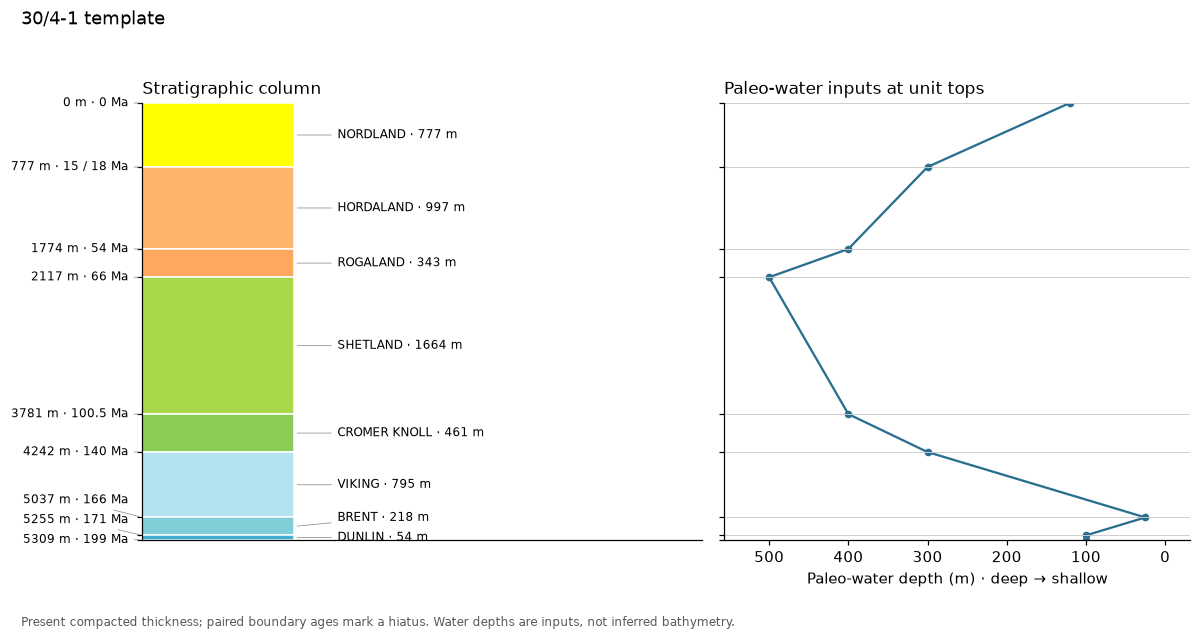

In [2]:
%matplotlib inline
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
from pybasinsubs import data_path, app_core
from pybasinsubs.column import read_column
col = read_column(data_path("template", "my_column_template.csv"), name="30/4-1 template")
fig = stratigraphic_column(col)
display(fig)
plt.close(fig)


### 2 · Porosity–depth relations

Use the actual lithology constants. Optional measured porosity records can be passed to `compaction_relations(col, measured=records)` (depth_m below seafloor, porosity as a fraction, optional lithology); these overlays do not alter the model.

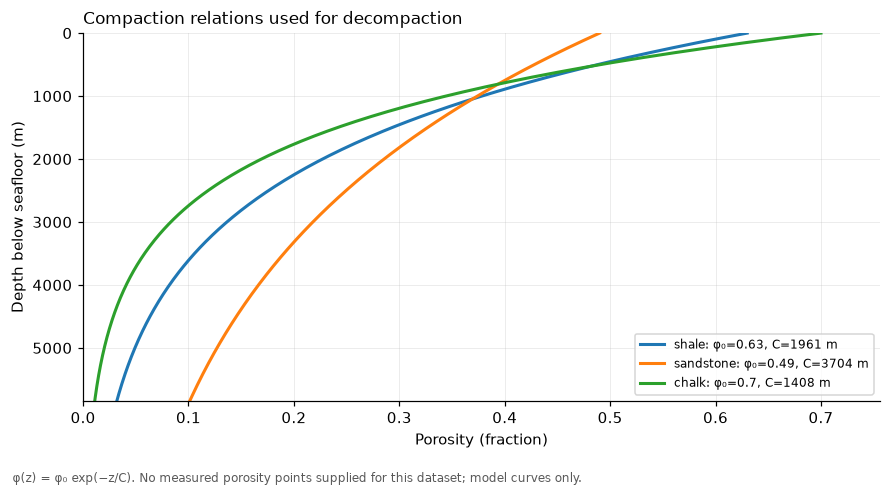

In [3]:
fig = compaction_relations(col)
display(fig)
plt.close(fig)


### 3 · Geohistory, then its data table

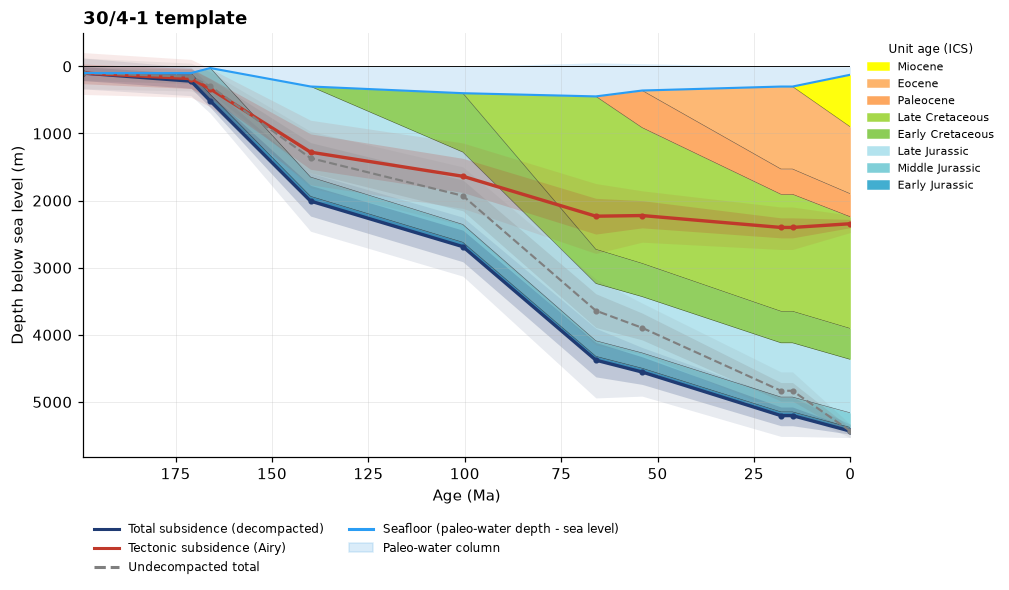

,node,age_Ma,undecompacted_total_m,undecompacted_total_m_sd,undecompacted_total_m_p2.5,undecompacted_total_m_p16,undecompacted_total_m_p50,undecompacted_total_m_p84,undecompacted_total_m_p97.5,total_subsidence_m,...,water_depth_m_p84,water_depth_m_p97.5,sea_level_m,sea_level_m_sd,sea_level_m_p2.5,sea_level_m_p16,sea_level_m_p50,sea_level_m_p84,sea_level_m_p97.5,age_Ma_sd
0,base (TD),199.0,100.00,113.24,-124.41,4.62,101.41,211.40,335.77,100.00,...,149.19,186.92,0.00,104.04,-204.29,-104.87,-6.59,94.83,216.30,2.00
1,DUNLIN,171.0,154.00,107.59,-47.99,42.96,155.91,255.06,366.74,220.30,...,146.46,192.78,0.00,97.86,-188.87,-99.36,0.18,94.23,196.95,1.93
2,BRENT,166.0,297.00,100.10,83.95,187.86,298.55,393.21,473.56,516.14,...,47.88,72.42,0.00,97.71,-171.47,-96.49,2.58,110.52,203.52,1.48
3,VIKING,140.0,1367.00,220.52,968.87,1136.26,1357.07,1586.80,1807.50,2007.04,...,483.91,705.07,0.00,100.71,-197.46,-95.82,1.15,106.37,194.30,1.92
4,CROMER KNOLL,100.5,1928.00,225.10,1498.66,1692.73,1924.43,2151.54,2369.00,2685.72,...,590.43,784.17,0.00,100.79,-194.85,-97.34,0.79,99.04,196.84,0.99
5,SHETLAND,66.0,3639.82,255.26,3170.53,3388.08,3643.02,3890.06,4149.92,4377.14,...,759.90,1024.78,52.18,1.11,50.19,51.14,52.21,53.40,54.39,0.53
6,ROGALAND,54.0,3895.20,195.38,3526.80,3675.57,3880.38,4075.08,4286.40,4553.78,...,587.77,771.54,39.80,1.99,36.10,37.80,39.88,41.82,43.59,1.02
7,HORDALAND,18.0,4833.05,146.47,4551.66,4711.08,4853.06,4986.74,5138.55,5202.85,...,450.63,603.50,-1.05,0.69,-2.45,-1.74,-1.04,-0.39,0.26,1.98
8,start of NORDLAND,15.0,4833.05,146.47,4551.66,4711.08,4853.06,4986.74,5138.55,5202.85,...,450.63,603.50,-1.05,0.69,-2.45,-1.74,-1.04,-0.39,0.26,0.00
9,NORDLAND,0.0,5433.89,47.50,5332.89,5385.67,5434.08,5479.79,5530.61,5433.89,...,130.17,137.97,-4.39,2.55,-9.11,-6.95,-4.40,-1.62,0.49,0.00


In [4]:
out = app_core.run_case(col, n=500, heat_flow_mW=59)
plt.close(out["fig_maturity"])  # display thermal figure only in section 4
display(out["fig_geohistory"])
plt.close(out["fig_geohistory"])
display(out["summary"].round(2))


### 4 · Thermal history, then its tables

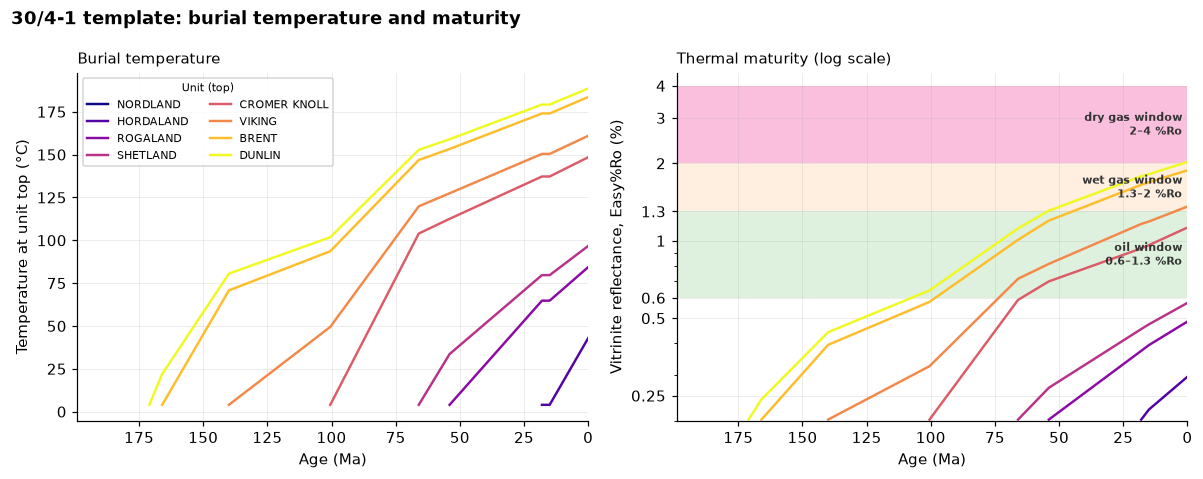

,unit,present_T_C,present_Ro,window
0,NORDLAND,4.00,NaN,
1,HORDALAND,42.88,0.30,immature
2,ROGALAND,84.33,0.49,immature
3,SHETLAND,96.67,0.57,immature
4,CROMER KNOLL,148.46,1.13,oil
5,VIKING,160.97,1.36,wet gas
6,BRENT,183.60,1.88,wet gas
7,DUNLIN,188.58,2.02,dry gas


In [5]:
display(out["fig_maturity"])
plt.close(out["fig_maturity"])
display(out["maturity"].round(2))


## Your own 2-D inputs

Supply both horizons and units CSVs, plus optional fault sticks. Blank uploads use VG1. `flex2d.read_section_template()` locates the paired files; `app_core.load_section(horizons, units, faults)` accepts their bytes or paths. See the bundled templates for column names. Do not treat assumed water depths as measured bathymetry.


## 2-D analysis order — fixed-trace VG1 prototype

Inspect the present-day input and the compaction model before explicitly reconstructing growth. The following cells use the same helpers and default traces as the app. No tip-extension or trace-position assist is applied.

### 1 · Present-day interpreted section

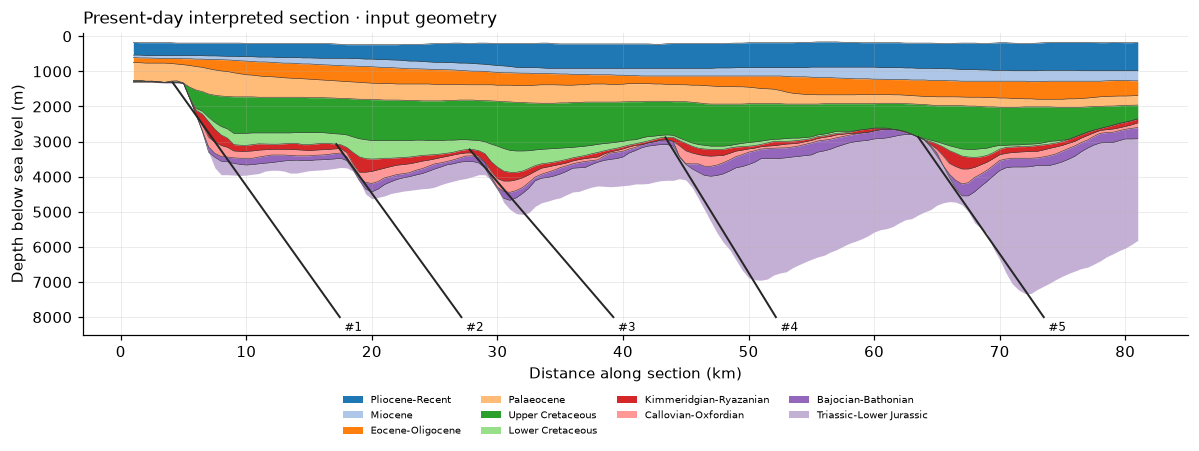

In [6]:
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
from pybasinsubs import app_core as analysis_core
analysis_section, analysis_faults = analysis_core.load_section()
fig = interpreted_section(analysis_section, analysis_faults)
display(fig)
plt.close(fig)


### 2 · Porosity–depth relations

These central lithology curves are the actual decompaction inputs. VG1 contains no measured porosity points; the helper does not manufacture scatter or refit the curves.

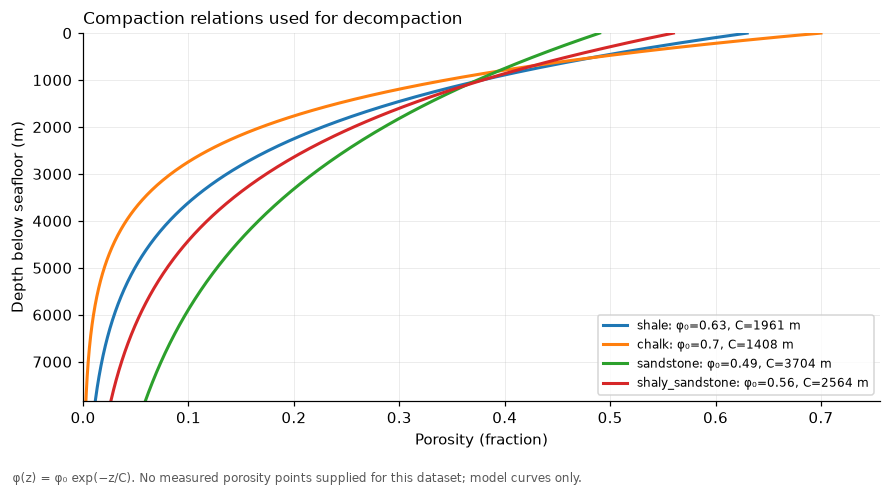

In [7]:
fig = compaction_relations(analysis_section)
display(fig)
plt.close(fig)


### 3 · Explicit growth reconstruction — one timestep per figure

This is nonnegative, regularized vertical-shear **apparent throw**, not resolved down-dip slip, geological heave or curved-fault balancing. Zero is assumed. The oldest interval retains 170.3-Ma geometry, not an inferred 252-Ma restoration. Rates show spatial / fitting-sensitivity ranges, not confidence intervals. Remaining traces are slipped and top-clipped; #1–#5 labels default on. All timestep figures share one shape and all-timestep axis limits.

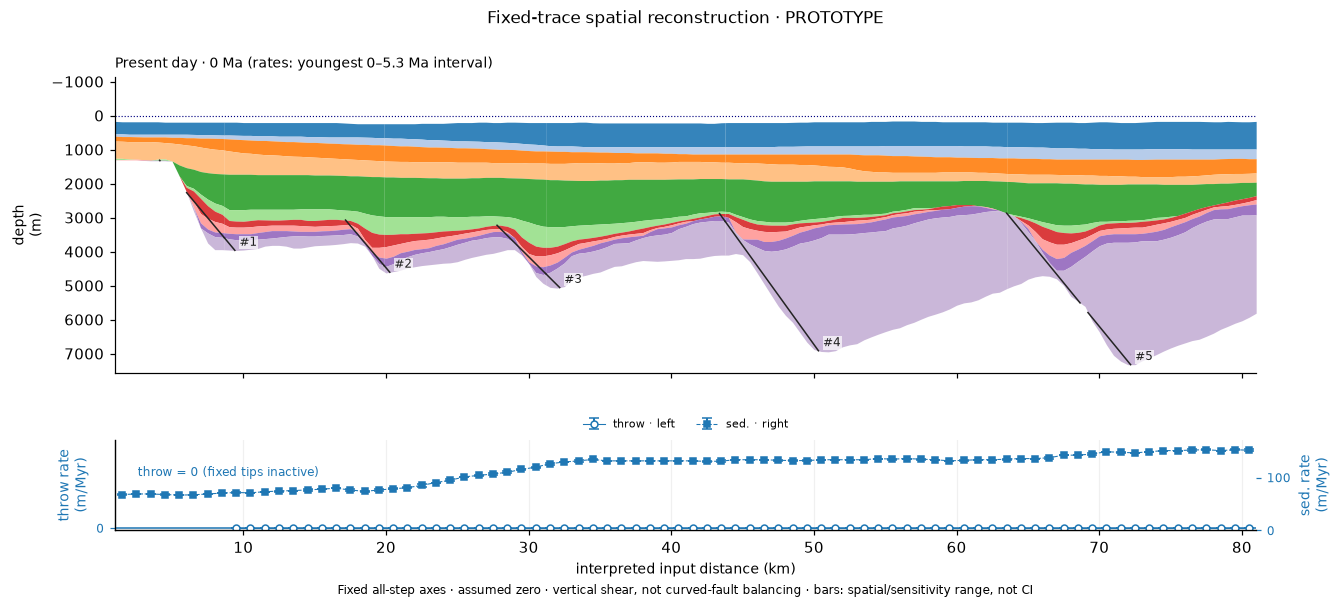

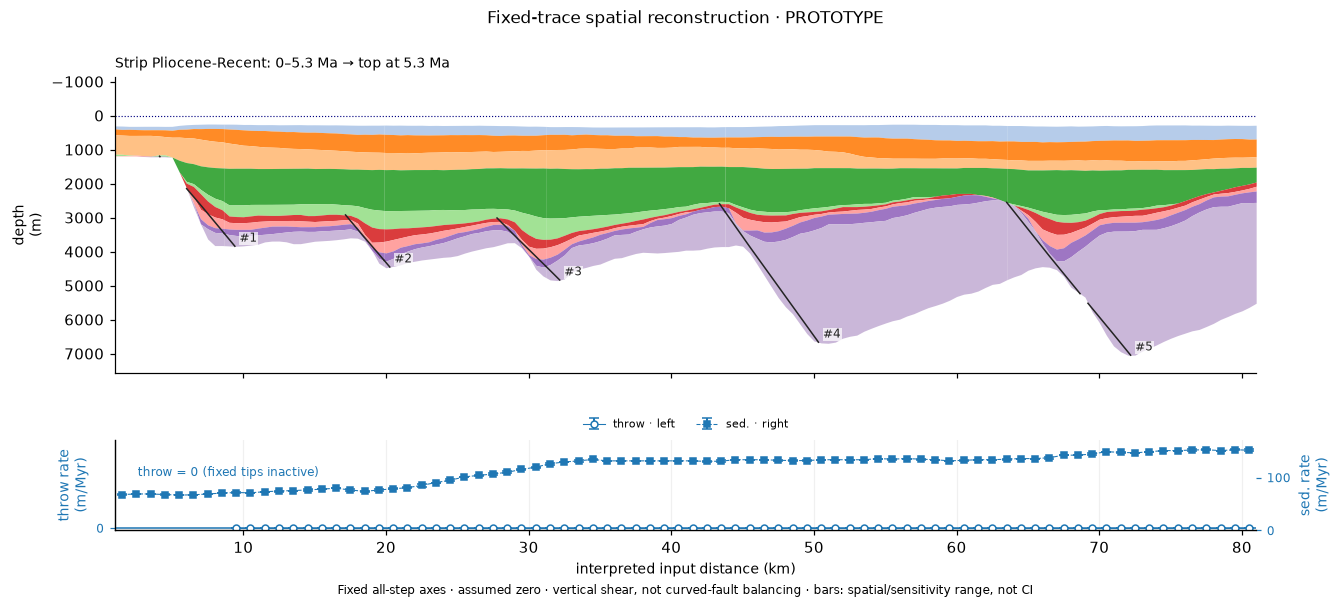

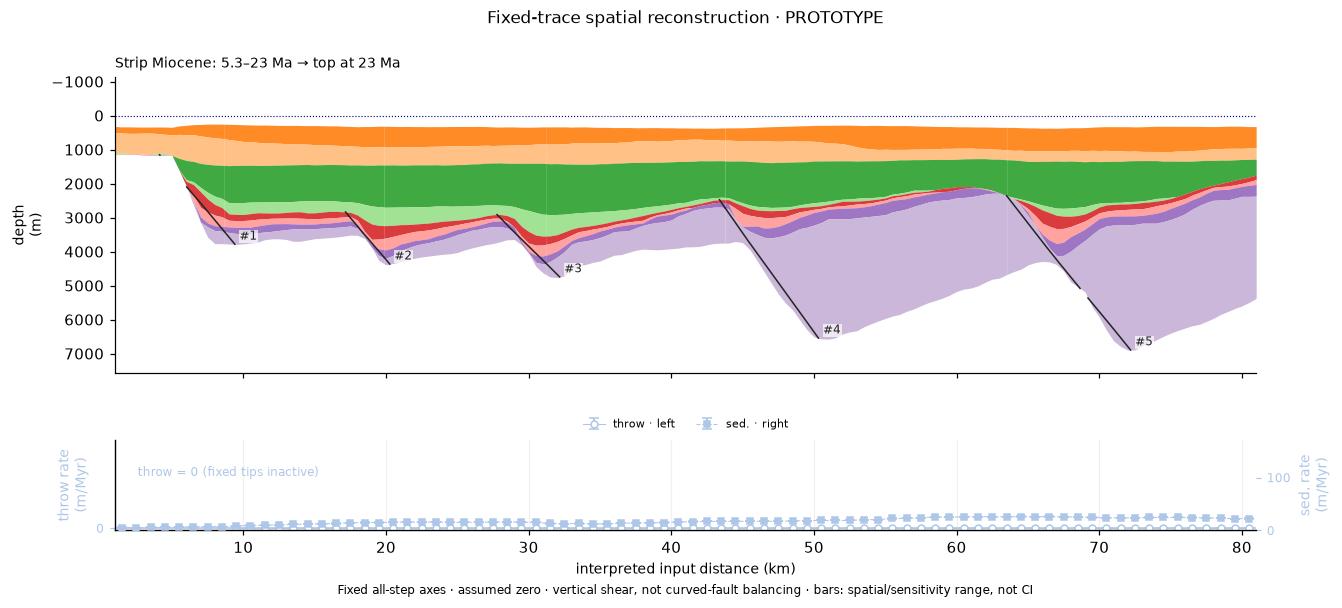

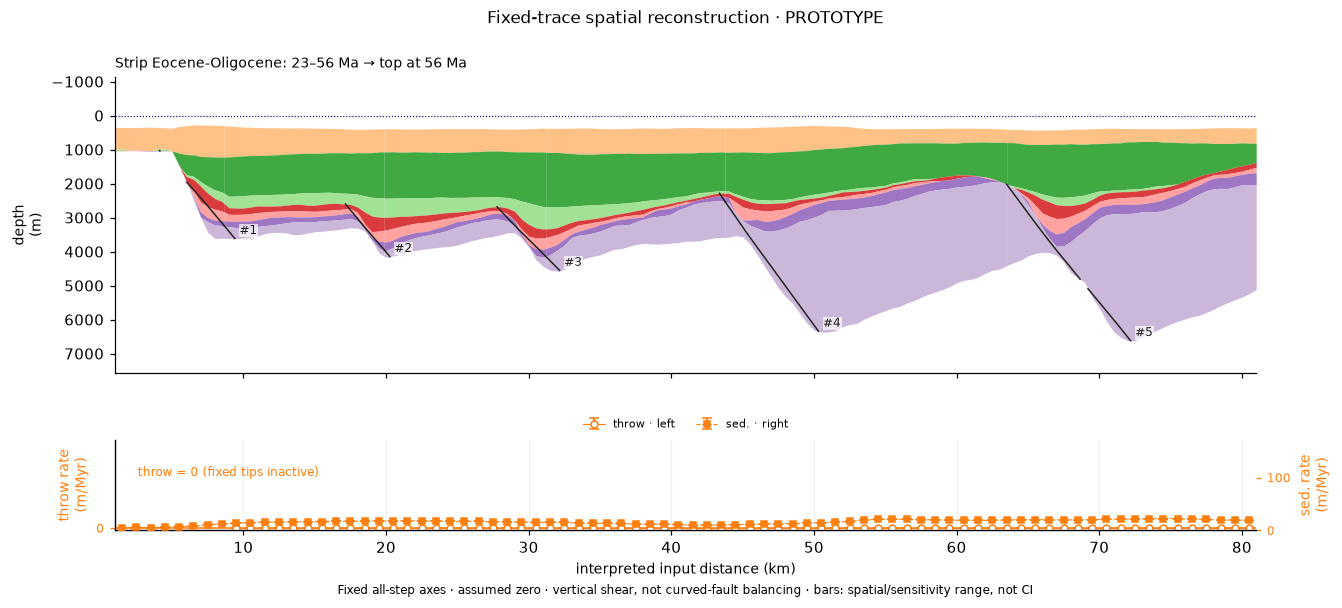

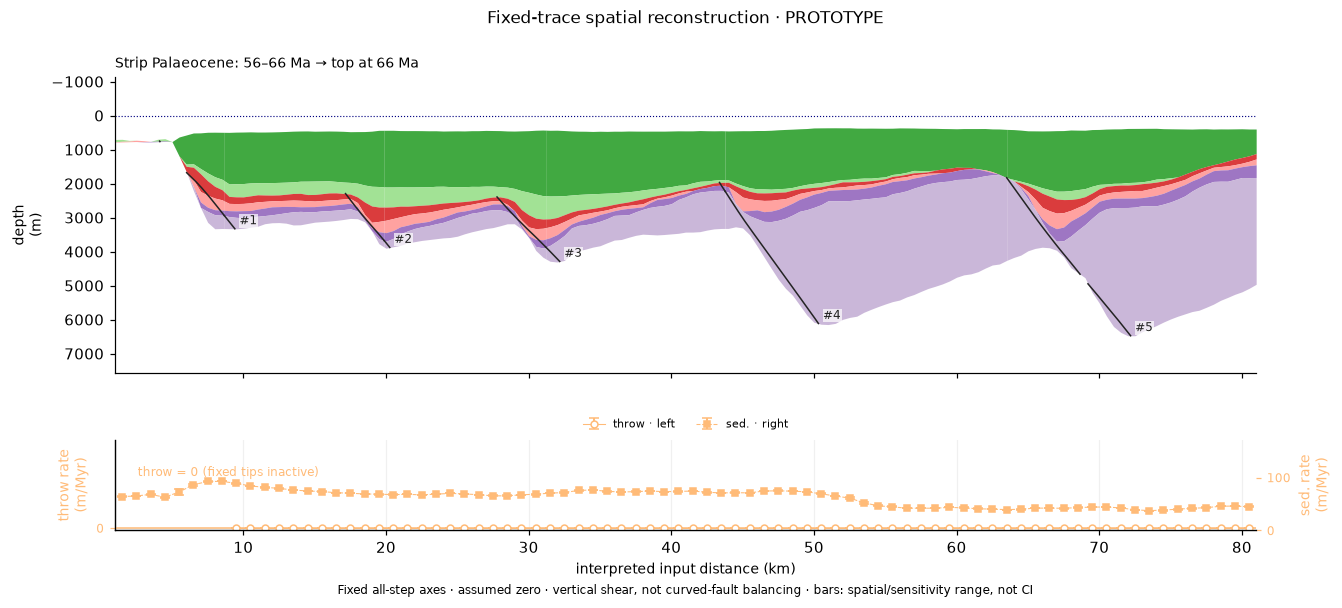

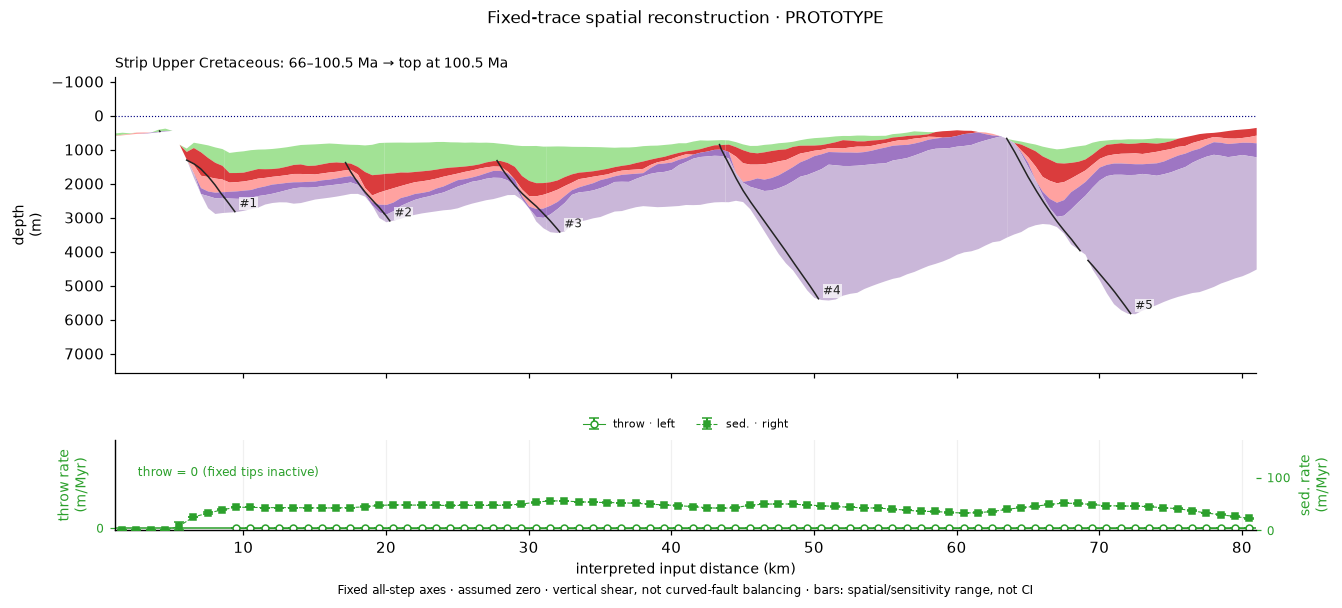

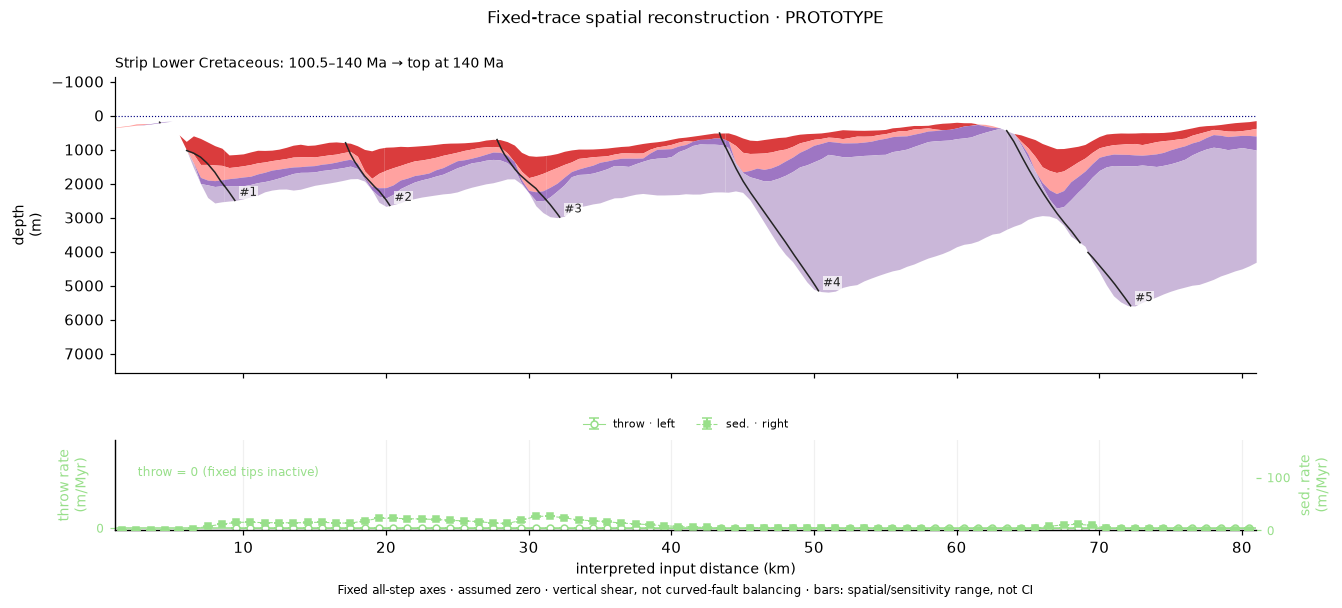

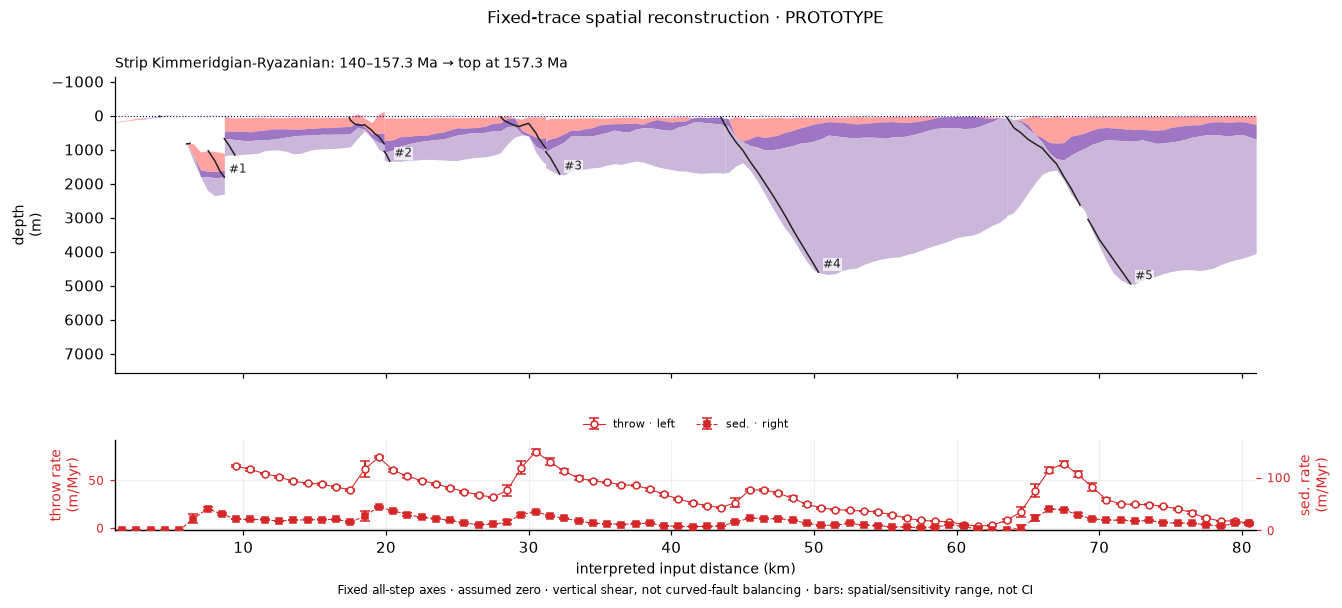

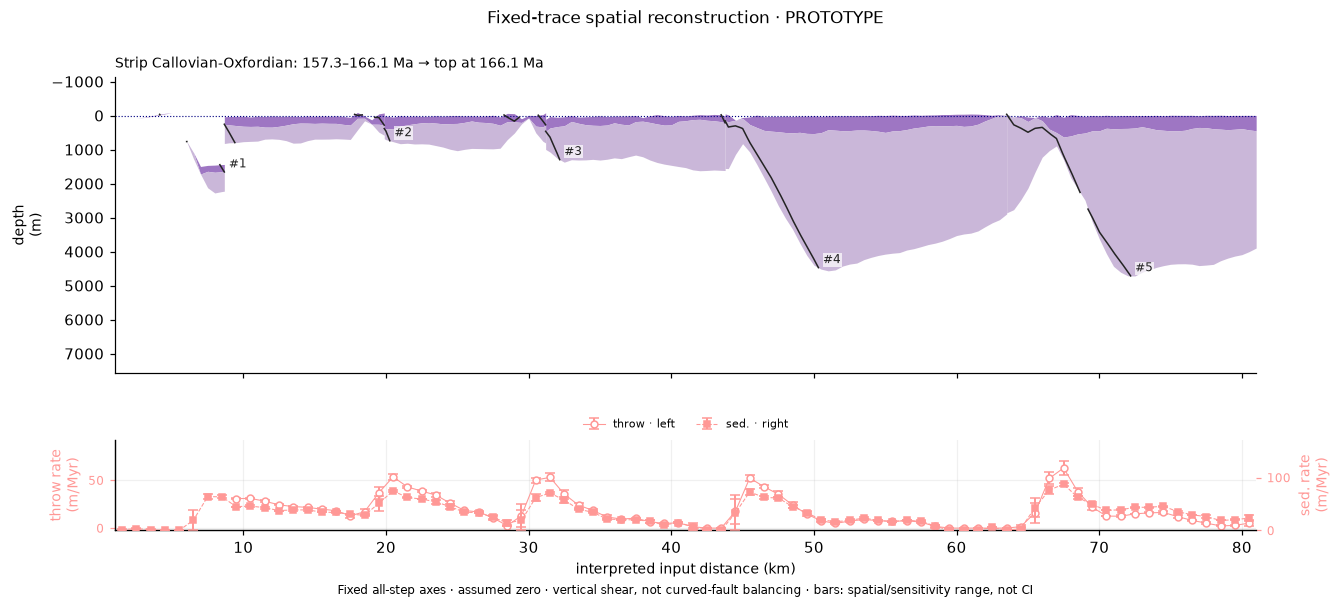

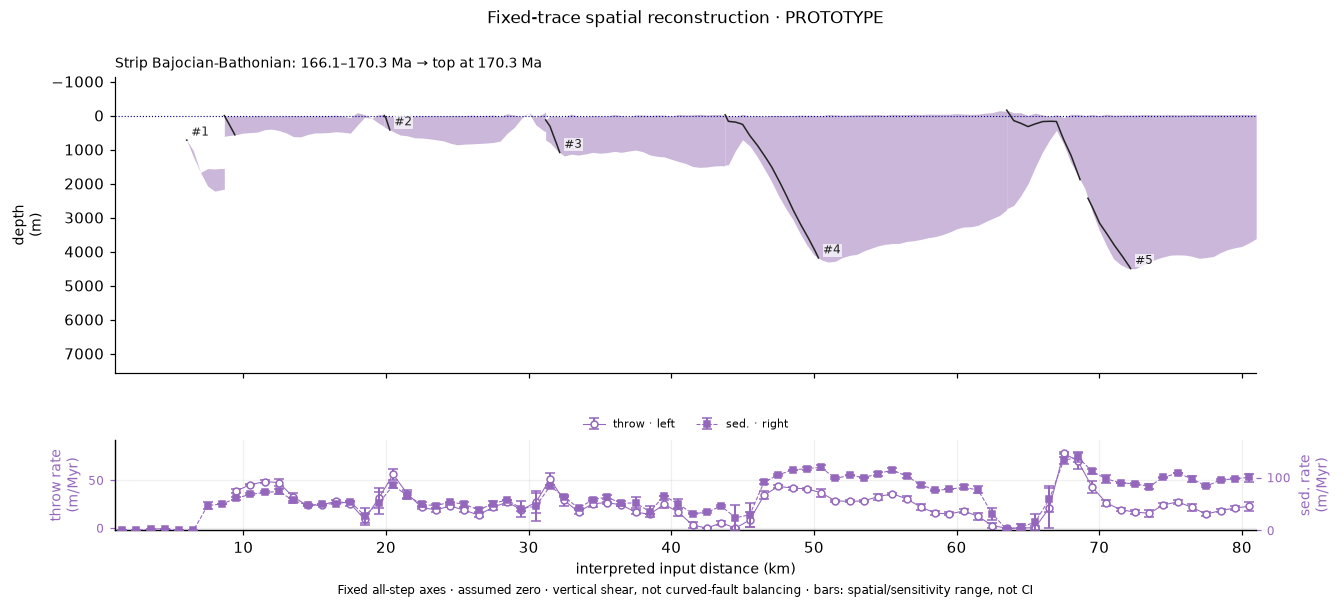

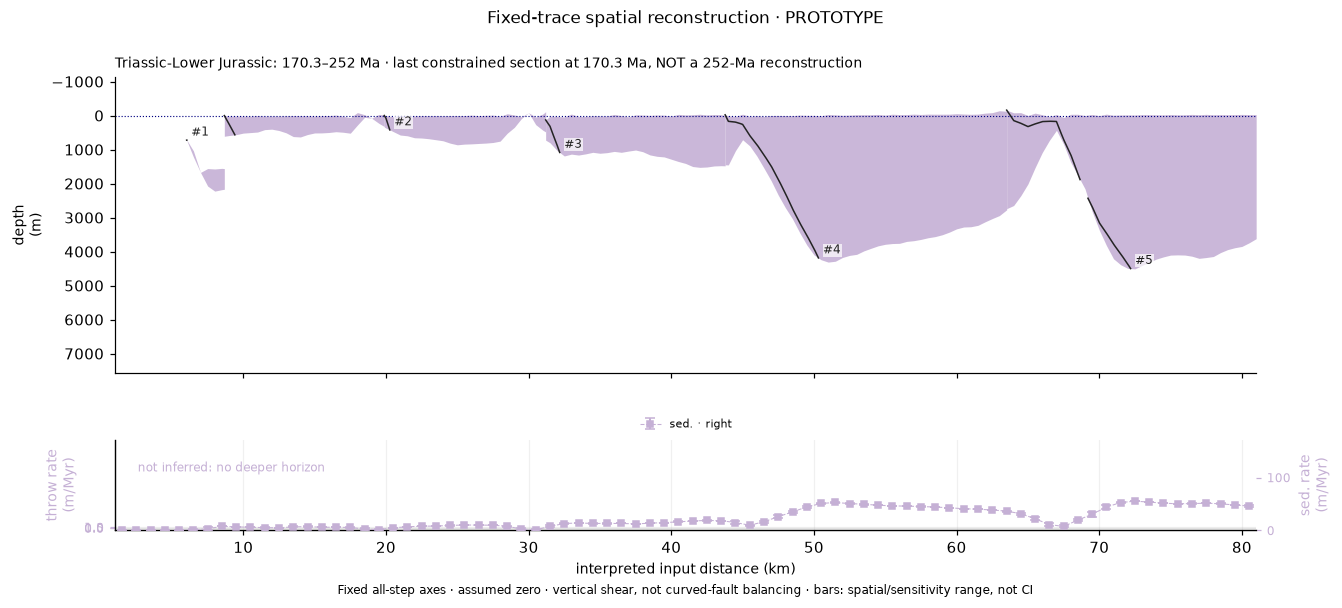

In [8]:
from pybasinsubs.growth_spatial import reconstruct_spatial_growth, binned_spatial_rates
from pybasinsubs.growth_display import plot_growth_frames
# Explicit call: do not reconstruct while loading or inspecting the inputs.
analysis_growth = reconstruct_spatial_growth(analysis_section, analysis_faults, make_figures=False)
analysis_sensitivity = [
    reconstruct_spatial_growth(analysis_section, analysis_faults, make_figures=False,
                              datum_sigma_m=d, growth_sigma_m=g)
    for d, g in [(125., 500.), (175., 700.)]
]
analysis_bins = binned_spatial_rates(analysis_growth, sensitivity=analysis_sensitivity)
# Set show_fault_numbers=False to hide trace numbers. Each figure is one timestep.
for fig in plot_growth_frames(analysis_growth, bins=analysis_bins, show_fault_numbers=True):
    display(fig)
    plt.close(fig)


### 4 · Summary diagnostics and tables

Inferred increments and binned spatial rates are shown after the restored frames. The browser provides a vertical geological-time slider (modern at top), playback and CSV downloads.

In [9]:
display(analysis_growth.history.round(3))
display(analysis_bins.round(3))


,unit,fault,age_top_Ma,age_base_Ma,duration_Myr,throw_m,heave_m,dip_slip_m,rotation_deg,throw_m_Myr,heave_m_Myr,dip_slip_m_Myr,rotation_deg_Myr,rotation_kind,inference,auxiliary_contact_translation_increment_m,auxiliary_contact_translation_m_Myr
0,Pliocene-Recent,F1,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
1,Pliocene-Recent,F2,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
2,Pliocene-Recent,F3,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
3,Pliocene-Recent,F4,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
4,Pliocene-Recent,F5,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
5,Miocene,F1,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
6,Miocene,F2,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
7,Miocene,F3,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
8,Miocene,F4,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
9,Miocene,F5,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0


,unit,x_bin_lo_m,x_bin_hi_m,x_m,kind,rate_m_Myr,range_low_m_Myr,range_high_m_Myr,n,errorbar
0,Pliocene-Recent,1000.0,2000.0,1500.0,sedimentation,67.915,66.830,69.000,2,within-bin spatial + fit-sensitivity range; NO...
1,Pliocene-Recent,2000.0,3000.0,2500.0,sedimentation,69.000,69.000,69.000,2,within-bin spatial + fit-sensitivity range; NO...
2,Pliocene-Recent,3000.0,4000.0,3500.0,sedimentation,69.000,69.000,69.000,2,within-bin spatial + fit-sensitivity range; NO...
3,Pliocene-Recent,4000.0,5000.0,4500.0,sedimentation,67.925,66.849,69.000,2,within-bin spatial + fit-sensitivity range; NO...
4,Pliocene-Recent,5000.0,6000.0,5500.0,sedimentation,66.849,66.849,66.849,2,within-bin spatial + fit-sensitivity range; NO...
...,...,...,...,...,...,...,...,...,...,...
1443,Triassic-Lower Jurassic,76000.0,77000.0,76500.0,sedimentation,50.769,50.495,51.043,2,within-bin spatial + fit-sensitivity range; NO...
1444,Triassic-Lower Jurassic,77000.0,78000.0,77500.0,sedimentation,51.612,51.531,51.693,2,within-bin spatial + fit-sensitivity range; NO...
1445,Triassic-Lower Jurassic,78000.0,79000.0,78500.0,sedimentation,50.348,49.664,51.032,2,within-bin spatial + fit-sensitivity range; NO...
1446,Triassic-Lower Jurassic,79000.0,80000.0,79500.0,sedimentation,48.243,47.927,48.559,2,within-bin spatial + fit-sensitivity range; NO...


## Local browser app

Run `pybasinsubs-app` (or `python -m pybasinsubs.webapp`). The two start-page buttons open column and section workflows. Fault editor stays in the top navigation. Results use the same input/model figures and analysis order as these cells; ordinary Run section shows the present day, and growth is a separate explicit action. Files stay on your computer. The browser offers CSV downloads, vertical geological time, playback and a default-on fault-number toggle.

2-D wizard steps: **1** open section → **2** compaction → **3** Run section → **4** Reconstruct growth / Show rates → **5** explicitly Compute thermal history → **6** output / export. Thermal reuses cached growth geometries; it never runs on load, Run section, or Reconstruct growth. Notebook 8 shows the whole-section Easy%Ro overlays, three fixed 0–100% multi-unit window line strips, timestep slider and optional GIF export.
